# 10 — Incidência, indicadores do programa e qualidade do registro

**Análises do plano:** A1 (incidência por 100 mil), A2 (indicadores do programa x metas), A7 (forma clínica e
confirmação laboratorial), A12 (completude por cidade e ano) e os gráficos da lista "Consertar" da reunião
(pirâmide em %, proporção de desfechos, desfecho x alcoolismo em %, situação de rua + alcoolismo x abandono).

**Definições usadas em todo o notebook**

- Cidade = município de **residência** (Ilhéus 291360, Itabuna 291480), diagnóstico entre 2014 e 2024.
- Incidência = **casos novos** / população do ano (notebook 09) × 100 mil.
- Cura, abandono e óbito = coorte de **casos novos**, sem "mudança de diagnóstico" (padrão do Ministério da Saúde).
- Variáveis sim/não: "ignorado" e vazio ficam fora do denominador e são medidos à parte (seção 5).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path('..', 'src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import tb_utils as tb

tb.estilo()
df = tb.carrega_base()
ii = tb.residentes_ii(df)
pop = tb.carrega_populacao()
cidades = ['Ilhéus', 'Itabuna']
cores = tb.CORES_CIDADE
print(f'Residentes de Ilhéus e Itabuna, 2014-2024: {len(ii)} notificações')
ii.groupby('cidade').size().rename('notificações').to_frame()

Residentes de Ilhéus e Itabuna, 2014-2024: 3251 notificações


,notificações
cidade,
Ilhéus,1489
Itabuna,1762


## 1. Incidência de casos novos por 100 mil habitantes (A1)

Comparamos com a Bahia e o Brasil, calculados com os mesmos critérios (casos novos por residência) a partir da
tabela agregada do Brasil inteiro.

In [2]:
linhas = []
for cidade, cod in [('Ilhéus', tb.COD_ILHEUS), ('Itabuna', tb.COD_ITABUNA)]:
    for ano in tb.ANOS:
        casos = int(((ii['cidade'] == cidade) & (ii['ano_diag'] == ano) & ii['caso_novo']).sum())
        p = tb.pop_cidade_ano(pop, cod, ano)
        t, lo, hi = tb.taxa_100k(casos, p)
        linhas.append({'local': cidade, 'ano': ano, 'casos_novos': casos, 'populacao': p, 'taxa': t, 'ic_inf': lo, 'ic_sup': hi})

agreg = pd.read_csv(tb.PROCESSED / 'tb_brasil_agregado.csv.gz', dtype={'SG_UF': str, 'ID_MN_RESI': str, 'TRATAMENTO': str})
agreg = agreg[agreg['TRATAMENTO'].eq('1') & agreg['ano_diag'].between(2014, 2024)]
for local, filtro_casos, filtro_pop in [('Bahia', agreg['SG_UF'].eq('29'), pop['cod6'].str.startswith('29')),
                                        ('Brasil', agreg['SG_UF'].notna(), pop['cod6'].notna())]:
    for ano in tb.ANOS:
        casos = int(agreg.loc[filtro_casos & agreg['ano_diag'].eq(ano), 'casos'].sum())
        p = pop.loc[filtro_pop & pop['ano'].eq(ano), 'populacao'].sum()
        t, lo, hi = tb.taxa_100k(casos, p)
        linhas.append({'local': local, 'ano': ano, 'casos_novos': casos, 'populacao': p, 'taxa': t, 'ic_inf': lo, 'ic_sup': hi})

incid = pd.DataFrame(linhas)
incid.to_csv(tb.PROCESSED / 'incidencia_anual.csv', index=False)
incid.pivot(index='ano', columns='local', values='taxa').round(1)[['Ilhéus', 'Itabuna', 'Bahia', 'Brasil']]

local,Ilhéus,Itabuna,Bahia,Brasil
ano,,,,
2014,52.6,63.5,33.2,35.7
2015,53.3,53.8,30.6,35.3
2016,61.2,66.0,30.1,35.4
2017,55.3,72.7,30.8,36.8
2018,61.5,64.4,31.9,38.4
2019,75.5,79.0,32.0,38.7
2020,37.9,77.5,25.8,33.9
2021,59.2,79.7,28.3,35.5
2022,64.9,85.7,30.3,39.3


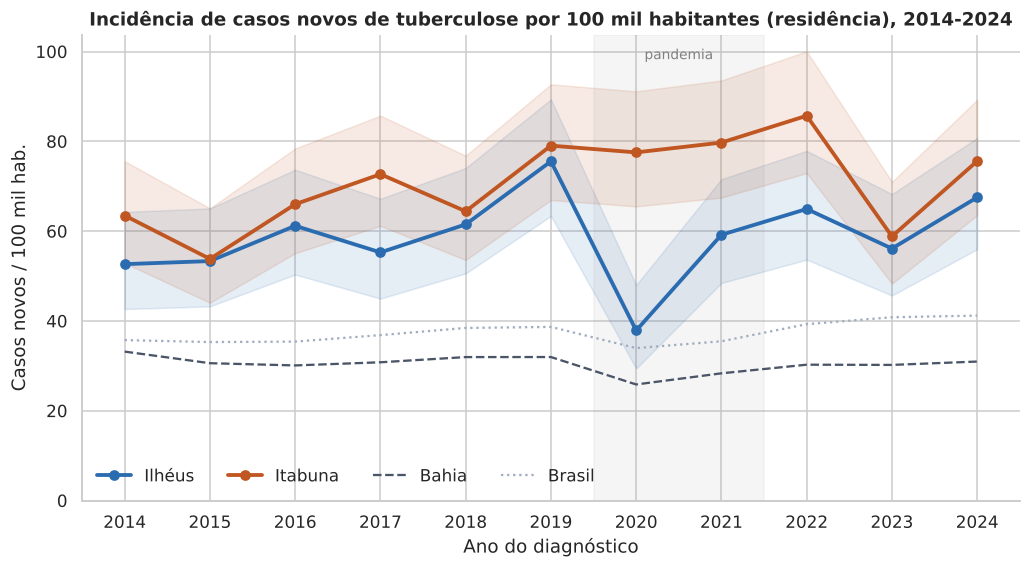

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
estilos = {'Ilhéus': dict(color=cores['Ilhéus'], lw=2.5, marker='o'), 'Itabuna': dict(color=cores['Itabuna'], lw=2.5, marker='o'),
           'Bahia': dict(color='#4a5568', lw=1.5, ls='--'), 'Brasil': dict(color='#a0aec0', lw=1.5, ls=':')}
for local, est in estilos.items():
    d = incid[incid['local'] == local]
    ax.plot(d['ano'], d['taxa'], label=local, **est)
    if local in cidades:
        ax.fill_between(d['ano'], d['ic_inf'], d['ic_sup'], color=est['color'], alpha=0.12)
ax.axvspan(2019.5, 2021.5, color='grey', alpha=0.08)
ax.text(2020.5, ax.get_ylim()[1] * 0.97, 'pandemia', ha='center', va='top', fontsize=9, color='grey')
ax.set_title('Incidência de casos novos de tuberculose por 100 mil habitantes (residência), 2014-2024')
ax.set_xlabel('Ano do diagnóstico'); ax.set_ylabel('Casos novos / 100 mil hab.')
ax.set_xticks(tb.ANOS); ax.legend(frameon=False, ncol=4, loc='lower left')
ax.set_ylim(bottom=0)
tb.salva_fig(fig, '10_incidencia_anual'); plt.show()

A faixa sombreada é o IC 95% de Poisson. Para comparar as duas cidades no período todo, calculamos a **razão
de taxas** (Itabuna / Ilhéus) com casos e pessoas-ano somados.

In [4]:
from statsmodels.stats.rates import test_poisson_2indep

def razao_taxas(a, b, df_inc=incid, anos=tb.ANOS):
    da = df_inc[(df_inc['local'] == a) & df_inc['ano'].isin(anos)]
    db = df_inc[(df_inc['local'] == b) & df_inc['ano'].isin(anos)]
    ca, pa, cb, pb = da['casos_novos'].sum(), da['populacao'].sum(), db['casos_novos'].sum(), db['populacao'].sum()
    rr = (ca / pa) / (cb / pb)
    se = np.sqrt(1 / ca + 1 / cb)
    teste = test_poisson_2indep(ca, pa, cb, pb, method='score')
    return {'comparação': f'{a} / {b}', 'taxa média ' + a: ca / pa * 1e5, 'taxa média ' + b: cb / pb * 1e5,
            'razão de taxas': rr, 'IC95% inf': rr * np.exp(-1.96 * se), 'IC95% sup': rr * np.exp(1.96 * se), 'p': teste.pvalue}

rt = pd.DataFrame([razao_taxas('Itabuna', 'Ilhéus'), razao_taxas('Itabuna', 'Bahia'), razao_taxas('Ilhéus', 'Bahia')])
rt.round(3)

,comparação,taxa média Itabuna,taxa média Ilhéus,razão de taxas,IC95% inf,IC95% sup,p,taxa média Bahia
0,Itabuna / Ilhéus,70.501,58.625,1.203,1.114,1.299,0.0,NaN
1,Itabuna / Bahia,70.501,NaN,2.321,2.204,2.444,0.0,30.372
2,Ilhéus / Bahia,NaN,58.625,1.930,1.821,2.046,0.0,30.372


## 2. Indicadores do programa de tuberculose x metas (A2)

| Indicador | Denominador | Meta de referência |
| --- | --- | --- |
| Cura | Casos novos encerrados (coorte) | ≥ 85% (OMS / Ministério da Saúde) |
| Abandono | Casos novos encerrados (coorte) | ≤ 5% (OMS / Ministério da Saúde) |
| Óbito por TB | Casos novos encerrados (coorte) | quanto menor melhor |
| Testagem para HIV | Casos novos | 100% (recomendação do Ministério da Saúde) |
| Cultura realizada | Casos novos pulmonares | crescente (recomendada para todos) |
| Contatos examinados | Contatos identificados de casos novos pulmonares | ≥ 70% (Ministério da Saúde) |
| TDO realizado | Casos novos com o campo preenchido | crescente |

A coorte de cura de um ano só fecha no ano seguinte; por isso mostramos também o % ainda sem encerramento.

In [5]:
def indicadores(g):
    coorte = g[g['coorte_casos_novos']]
    encerr = coorte[coorte['desfecho'] != 'Sem encerramento']
    cn = g[g['caso_novo']]
    cnp = cn[cn['pulmonar']]
    contatos = cnp[['n_contatos', 'n_contatos_examinados']].dropna()
    return pd.Series({
        'casos novos': len(cn),
        'cura (%)': 100 * encerr['cura'].mean(),
        'abandono (%)': 100 * encerr['abandono'].mean(),
        'óbito por TB (%)': 100 * encerr['obito_tb'].mean(),
        'sem encerramento (%)': 100 * (coorte['desfecho'] == 'Sem encerramento').mean(),
        'testagem HIV (%)': 100 * cn['hiv_testado'].mean(),
        'HIV positivo entre testados (%)': 100 * (cn['hiv'] == 'Positivo').sum() / cn['hiv_testado'].sum(),
        'cultura realizada, pulmonares (%)': 100 * cnp['cultura_realizada'].mean(),
        'TRM realizado, pulmonares (%)': 100 * cnp['trm_realizado'].mean(),
        'contatos examinados (%)': 100 * contatos['n_contatos_examinados'].sum() / contatos['n_contatos'].sum(),
        'TDO realizado (%)': 100 * cn['tdo'].mean(),
        'TDO preenchido (%)': 100 * cn['tdo'].notna().mean(),
    })

painel_periodo = ii.groupby('cidade').apply(indicadores).T
painel_periodo['Meta'] = ['', '≥ 85', '≤ 5', '', '', '100', '', '', '', '≥ 70', '', '']
painel_periodo.round(1)

cidade,Ilhéus,Itabuna,Meta
casos novos,1161.0,1482.0,
cura (%),78.8,74.5,≥ 85
abandono (%),11.6,13.2,≤ 5
óbito por TB (%),2.3,5.8,
sem encerramento (%),4.8,0.7,
testagem HIV (%),63.1,70.3,100
HIV positivo entre testados (%),11.8,9.6,
"cultura realizada, pulmonares (%)",41.7,16.4,
"TRM realizado, pulmonares (%)",1.2,1.7,
contatos examinados (%),48.6,33.3,≥ 70


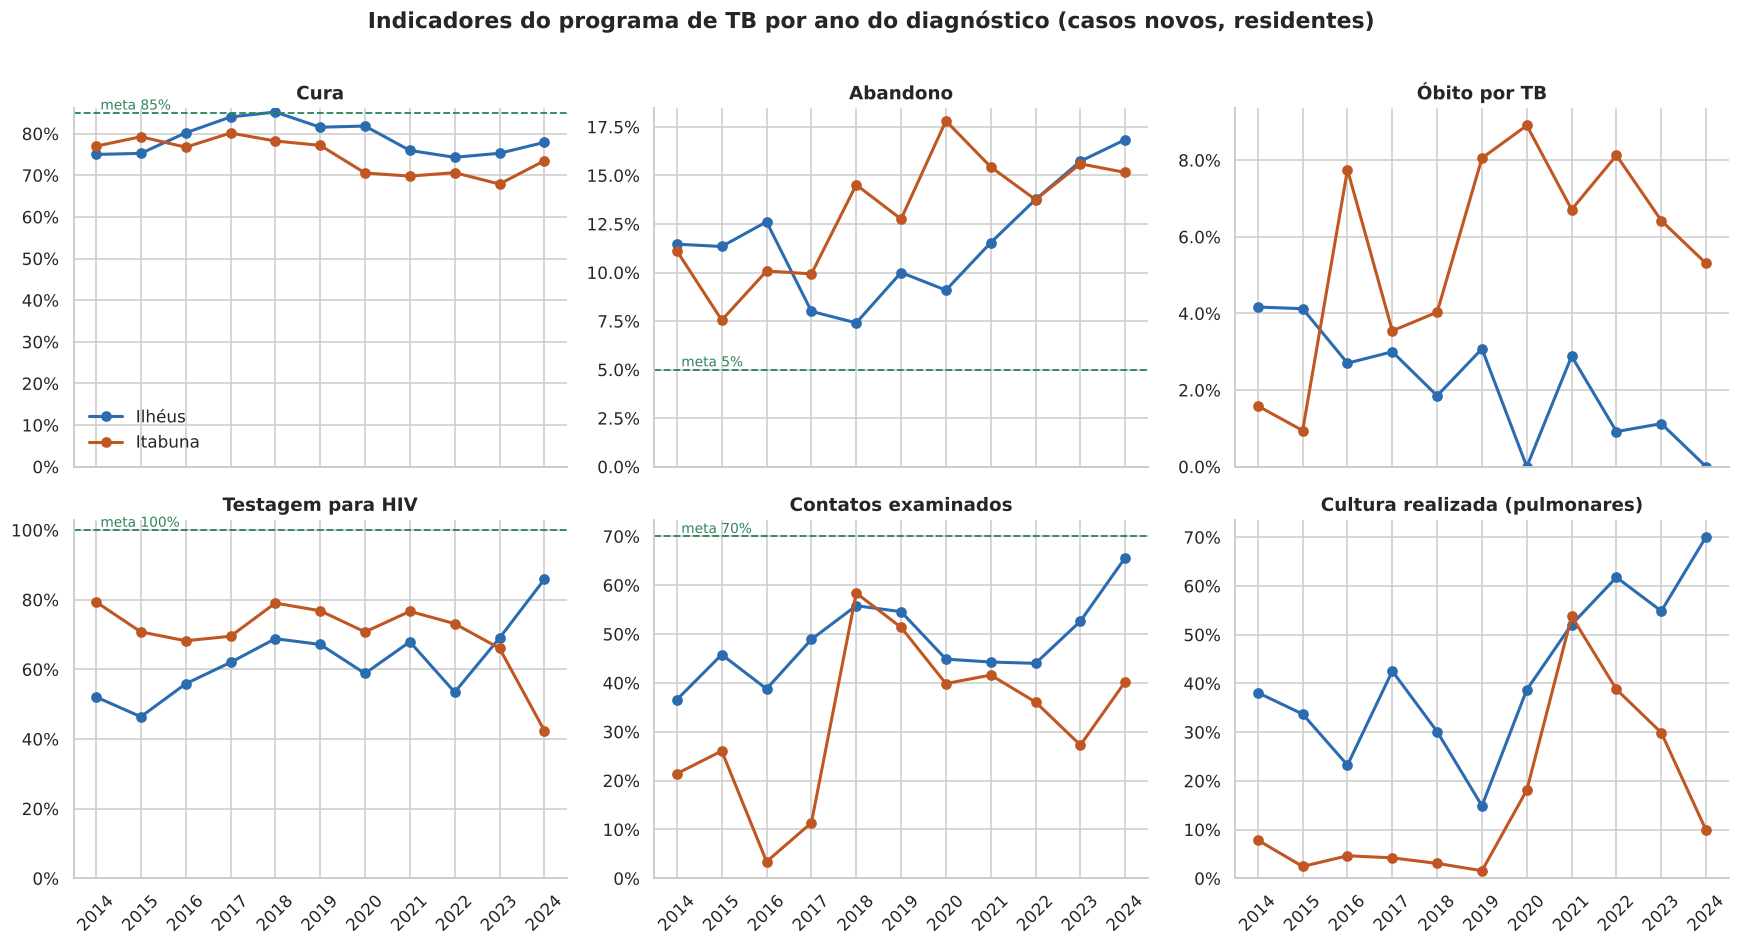

In [6]:
painel_ano = ii.groupby(['cidade', 'ano_diag']).apply(indicadores).reset_index()
painel_ano.to_csv(tb.PROCESSED / 'indicadores_programa_ano.csv', index=False)

graficos = [('cura (%)', 85, 'Cura'), ('abandono (%)', 5, 'Abandono'), ('óbito por TB (%)', None, 'Óbito por TB'),
            ('testagem HIV (%)', 100, 'Testagem para HIV'), ('contatos examinados (%)', 70, 'Contatos examinados'),
            ('cultura realizada, pulmonares (%)', None, 'Cultura realizada (pulmonares)')]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True)
for ax, (col, meta, titulo) in zip(axes.flat, graficos):
    for cidade in cidades:
        d = painel_ano[painel_ano['cidade'] == cidade]
        ax.plot(d['ano_diag'], d[col], marker='o', lw=2, color=cores[cidade], label=cidade)
    if meta is not None:
        ax.axhline(meta, color='#2f855a', ls='--', lw=1.2)
        ax.text(2014, meta, f' meta {meta}%', color='#2f855a', va='bottom', fontsize=9)
    ax.set_title(titulo); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylim(bottom=0)
axes[0, 0].legend(frameon=False)
for ax in axes[1]:
    ax.set_xticks(tb.ANOS); ax.tick_params(axis='x', rotation=45)
fig.suptitle('Indicadores do programa de TB por ano do diagnóstico (casos novos, residentes)', fontweight='bold', y=1.01)
fig.tight_layout(); tb.salva_fig(fig, '10_indicadores_programa'); plt.show()

**Atenção para 2024:** parte da coorte ainda estava sem encerramento quando a base foi extraída (ver coluna
"sem encerramento"), então a cura de 2024 tende a subir quando os dados forem atualizados.

## 3. Forma clínica e confirmação laboratorial (A7)

In [7]:
forma = (pd.crosstab(ii['cidade'], ii['forma'], normalize='index') * 100).round(1)
lab = (ii[ii['caso_novo'] & ii['pulmonar']].groupby('cidade')
       .agg(**{'pulmonares (n)': ('confirmacao_lab', 'size'),
               'confirmação laboratorial (%)': ('confirmacao_lab', lambda s: 100 * s.mean()),
               'baciloscopia realizada (%)': ('baciloscopia', lambda s: 100 * s.isin(['Positiva', 'Negativa']).mean()),
               'baciloscopia positiva (%)': ('baciloscopia', lambda s: 100 * (s == 'Positiva').mean())}).round(1))
display(forma)
display(lab)

forma,Extrapulmonar,Pulmonar,Pulmonar + extrapulmonar
cidade,,,
Ilhéus,9.8,87.7,2.4
Itabuna,15.8,83.8,0.4


,pulmonares (n),confirmação laboratorial (%),baciloscopia realizada (%),baciloscopia positiva (%)
cidade,,,,
Ilhéus,1033,68.9,87.8,60.3
Itabuna,1221,64.9,69.4,59.2


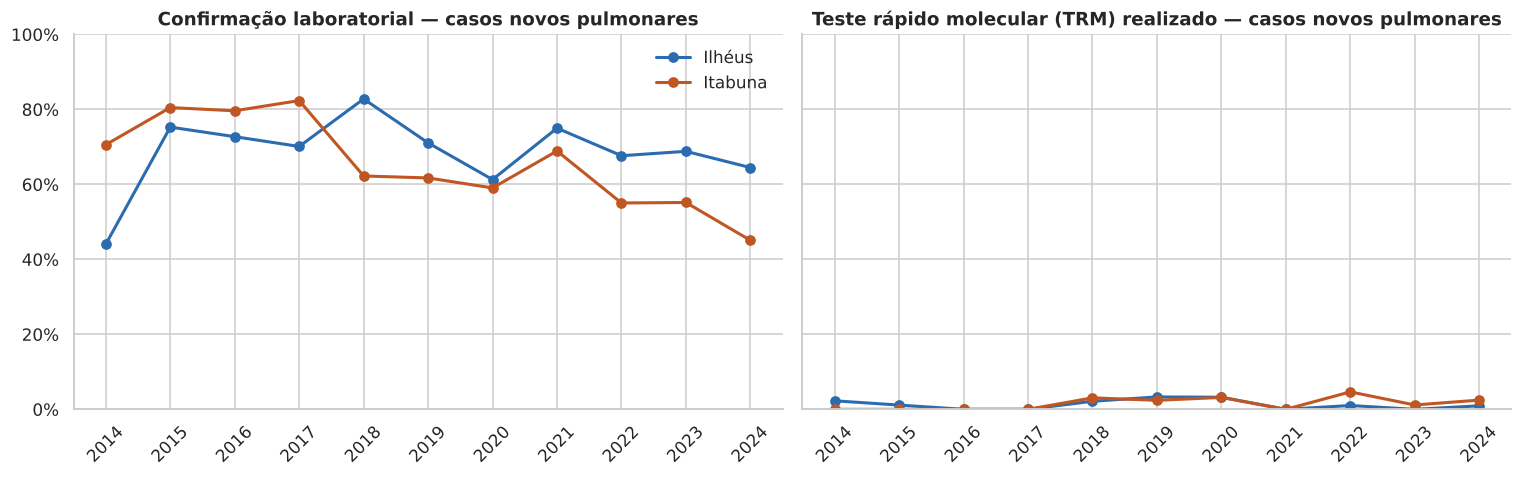

ano_diag,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
cidade,,,,,,,,,,,
Ilhéus,2.3,1.1,0.0,0.0,2.2,3.3,3.2,0.0,1.0,0.0,0.9
Itabuna,0.0,0.0,0.0,0.0,3.1,2.4,3.2,0.0,4.7,1.2,2.5


In [8]:
trm_ano = (ii[ii['caso_novo'] & ii['pulmonar']].groupby(['ano_diag', 'cidade'])['trm_realizado'].mean().unstack() * 100)
lab_ano = (ii[ii['caso_novo'] & ii['pulmonar']].groupby(['ano_diag', 'cidade'])['confirmacao_lab'].mean().unstack() * 100)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, tab, titulo in [(axes[0], lab_ano, 'Confirmação laboratorial'), (axes[1], trm_ano, 'Teste rápido molecular (TRM) realizado')]:
    for cidade in cidades:
        ax.plot(tab.index, tab[cidade], marker='o', lw=2, color=cores[cidade], label=cidade)
    ax.set_title(f'{titulo} — casos novos pulmonares'); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xticks(tb.ANOS); ax.tick_params(axis='x', rotation=45); ax.set_ylim(0, 100)
axes[0].legend(frameon=False)
fig.tight_layout(); tb.salva_fig(fig, '10_confirmacao_laboratorial'); plt.show()
trm_ano.round(1).T

## 4. Completude do registro por cidade e ano (A12)

Percentual de fichas com a informação **útil** preenchida (excluindo vazio e "ignorado"). Esta seção responde
a parte das perguntas da reunião: várias diferenças entre as cidades podem ser diferenças de registro.

In [9]:
campos = {'raça/cor': ii['raca'].notna() & ii['raca'].ne('Ignorado'),
          'escolaridade': ii['escolaridade'].notna() & ~ii['escolaridade'].isin(['Ignorado']),
          'alcoolismo': ii['alcoolismo'].notna(), 'drogas ilícitas': ii['drogas_ilicitas'].notna(),
          'tabagismo': ii['tabagismo'].notna(), 'situação de rua': ii['situacao_rua'].notna(),
          'privado de liberdade': ii['privado_liberdade'].notna(), 'TDO': ii['tdo'].notna(),
          'resultado HIV': ii['hiv'].isin(['Positivo', 'Negativo']),
          'início do tratamento': ii['dias_diag_trat'].notna(), 'contatos': ii['n_contatos'].notna(),
          'desfecho': ii['desfecho'].ne('Sem encerramento')}
comp = pd.DataFrame(campos).astype(float).assign(cidade=ii['cidade'], ano=ii['ano_diag'])
comp_cidade = (comp.groupby('cidade').mean(numeric_only=True).T.drop(index='ano') * 100).round(1)
comp_cidade['diferença (Itabuna - Ilhéus)'] = comp_cidade['Itabuna'] - comp_cidade['Ilhéus']
comp_cidade.sort_values('diferença (Itabuna - Ilhéus)')

cidade,Ilhéus,Itabuna,diferença (Itabuna - Ilhéus)
TDO,90.2,46.9,-43.3
situação de rua,93.0,85.7,-7.3
tabagismo,86.8,80.0,-6.8
alcoolismo,89.9,84.4,-5.5
raça/cor,92.7,89.3,-3.4
drogas ilícitas,83.1,79.7,-3.4
privado de liberdade,92.9,91.9,-1.0
início do tratamento,96.9,96.7,-0.2
contatos,99.0,99.2,0.2
escolaridade,71.1,71.5,0.4


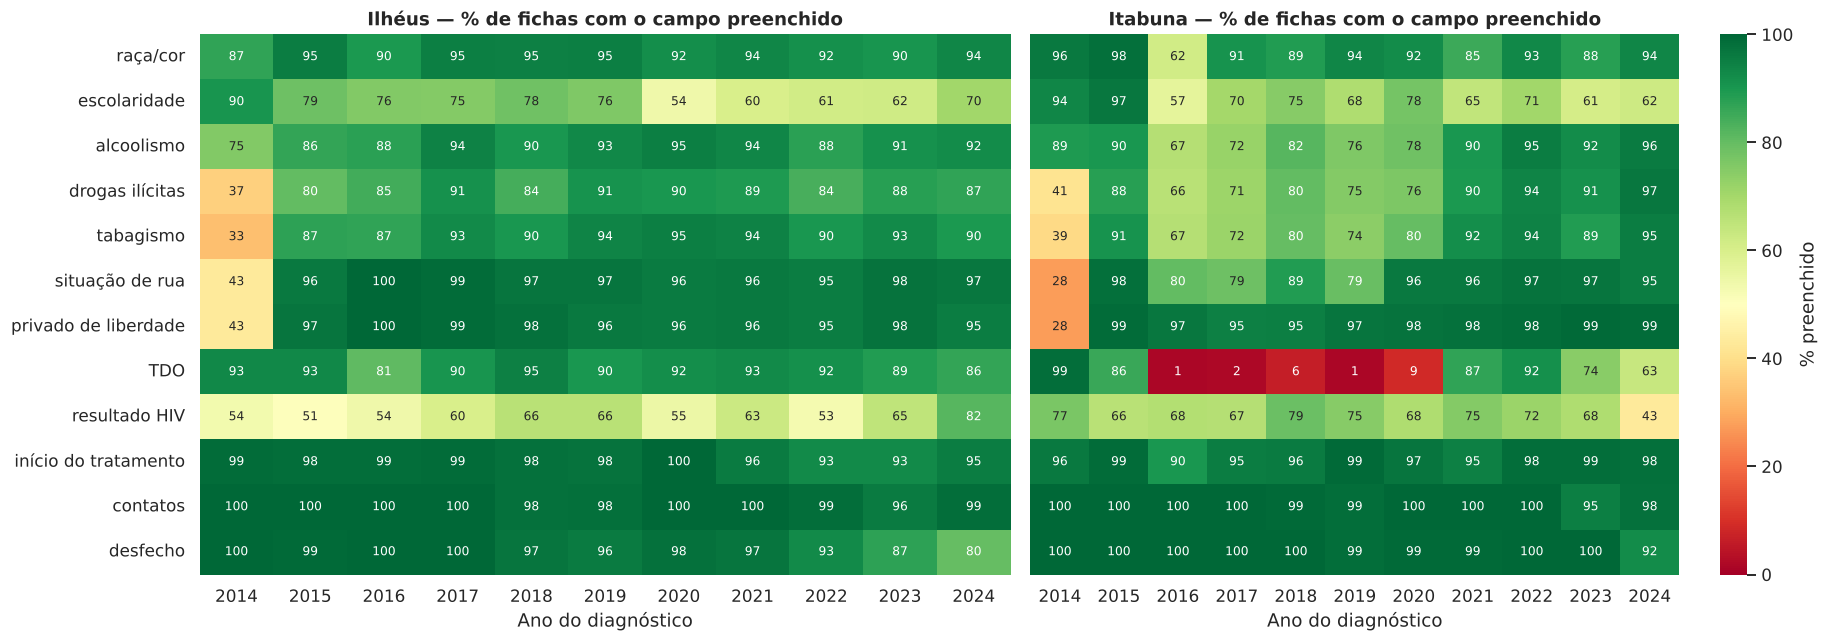

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, cidade in zip(axes, cidades):
    tab = (comp[comp['cidade'] == cidade].groupby('ano').mean(numeric_only=True).T * 100)
    sns.heatmap(tab, ax=ax, cmap='RdYlGn', vmin=0, vmax=100, annot=True, fmt='.0f', cbar=cidade == 'Itabuna',
                annot_kws={'size': 8}, cbar_kws={'label': '% preenchido'})
    ax.set_title(f'{cidade} — % de fichas com o campo preenchido'); ax.set_xlabel('Ano do diagnóstico'); ax.set_ylabel('')
fig.tight_layout(); tb.salva_fig(fig, '10_completude'); plt.show()

### O caso do TDO

A ficha tem dois campos de tratamento diretamente observado: `TRAT_SUPER` (antigo) e `TRATSUP_AT`
(acompanhamento). O antigo só aparece preenchido em 2014.

In [11]:
tdo = (ii.groupby(['cidade', 'ano_diag'])
       .agg(notificações=('tdo', 'size'), TDO_sim=('tdo', lambda s: int((s == 1).sum())),
            TDO_não=('tdo', lambda s: int((s == 0).sum())), TDO_vazio_ou_ignorado=('tdo', lambda s: int(s.isna().sum())),
            campo_antigo_sim=('tdo_2014_campo_antigo', lambda s: int((s == 1).sum()))))
tdo.unstack(0)

notificações         TDO_sim         TDO_não          \
cidade         Ilhéus Itabuna  Ilhéus Itabuna  Ilhéus Itabuna   
ano_diag                                                        
2014              114     141      27      66      79      73   
2015              132     119       7       0     116     102   
2016              144     151      13       0     103       2   
2017              125     173      11       1     102       2   
2018              133     143       8       0     118       9   
2019              163     170       6       1     141       1   
2020              102     170       4       0      90      15   
2021              142     184       5       1     127     159   
2022              153     194       4       0     136     178   
2023              126     145       1       0     111     108   
2024              155     172       5       0     129     109   

         TDO_vazio_ou_ignorado         campo_antigo_sim          
cidade                  Ilhéus Itabuna           Ilhéus Itabuna  
ano_diag                                                         
2014                         8       2               39      70  
2015                         9      17                0       0  
2016                        28     149                0       0  
2017                        12     170                0       0  
2018                         7     134                0       0  
2019                        16     168                0       0  
2020                         8     155                0       0  
2021                        10      24                0       0  
2022                        13      16                0       0  
2023                        14      37                0       0  
2024                        21      63                0       0

## 5. Gráficos refeitos (lista "Consertar" da reunião)

### 5.1 Pirâmide etária em %

Cada barra é a porcentagem dos casos **da própria cidade**, para que as duas pirâmides fiquem na mesma escala.

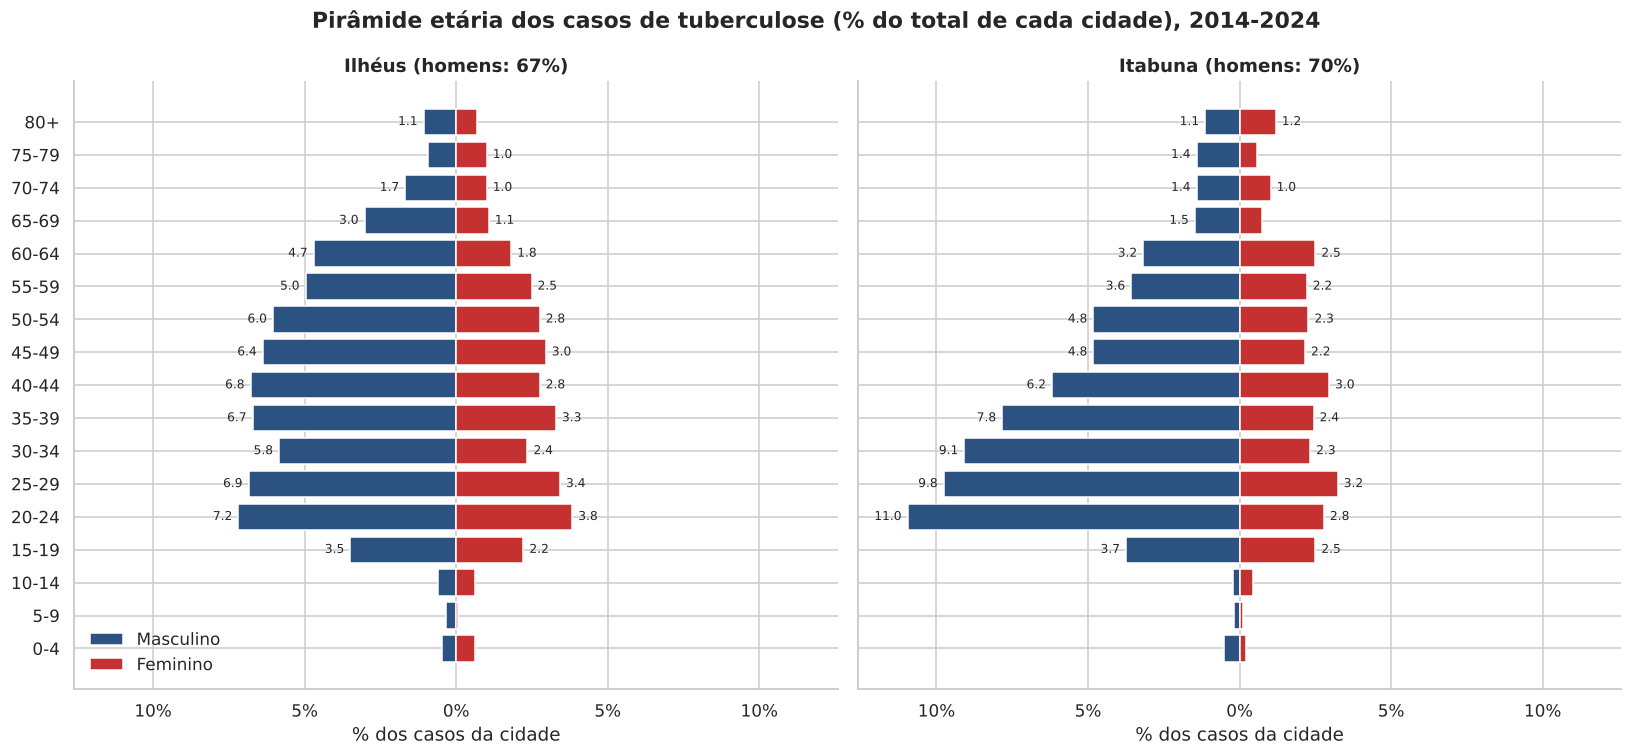

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
pir_all = (ii[ii['sexo'].isin(['Masculino', 'Feminino'])]
           .groupby(['cidade', 'faixa_etaria', 'sexo'], observed=False).size().rename('n').reset_index())
pir_all['pct'] = 100 * pir_all['n'] / pir_all.groupby('cidade')['n'].transform('sum')
lim = pir_all['pct'].max() * 1.15
for ax, cidade in zip(axes, cidades):
    d = pir_all[pir_all['cidade'] == cidade].pivot(index='faixa_etaria', columns='sexo', values='pct')
    y = np.arange(len(d))
    ax.barh(y, -d['Masculino'], color='#2c5282', label='Masculino')
    ax.barh(y, d['Feminino'], color='#c53030', label='Feminino')
    for yi, (m, f) in enumerate(zip(d['Masculino'], d['Feminino'])):
        if m >= 1: ax.text(-m - 0.2, yi, f'{m:.1f}', ha='right', va='center', fontsize=8)
        if f >= 1: ax.text(f + 0.2, yi, f'{f:.1f}', ha='left', va='center', fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(d.index)
    ax.set_xlim(-lim, lim)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{abs(v):.0f}%'))
    homens = 100 * (ii.loc[ii['cidade'] == cidade, 'sexo'] == 'Masculino').mean()
    ax.set_title(f'{cidade} (homens: {homens:.0f}%)'); ax.set_xlabel('% dos casos da cidade')
axes[0].legend(frameon=False, loc='lower left')
fig.suptitle('Pirâmide etária dos casos de tuberculose (% do total de cada cidade), 2014-2024', fontweight='bold')
fig.tight_layout(); tb.salva_fig(fig, '10_piramide_percentual'); plt.show()

### 5.2 Proporção de desfechos

Todos os casos novos (coorte), em % do total de cada cidade e ano. Agora "Transferência" aparece corretamente.

desfecho_grupo,Cura,Abandono,Óbito por TB,Óbito por outras causas,Transferência,TB-DR / falência / mudança de esquema,Sem encerramento
cidade,,,,,,,
Ilhéus,75.0,11.0,2.2,3.4,2.8,0.8,4.8
Itabuna,74.0,13.1,5.7,3.0,2.9,0.5,0.7


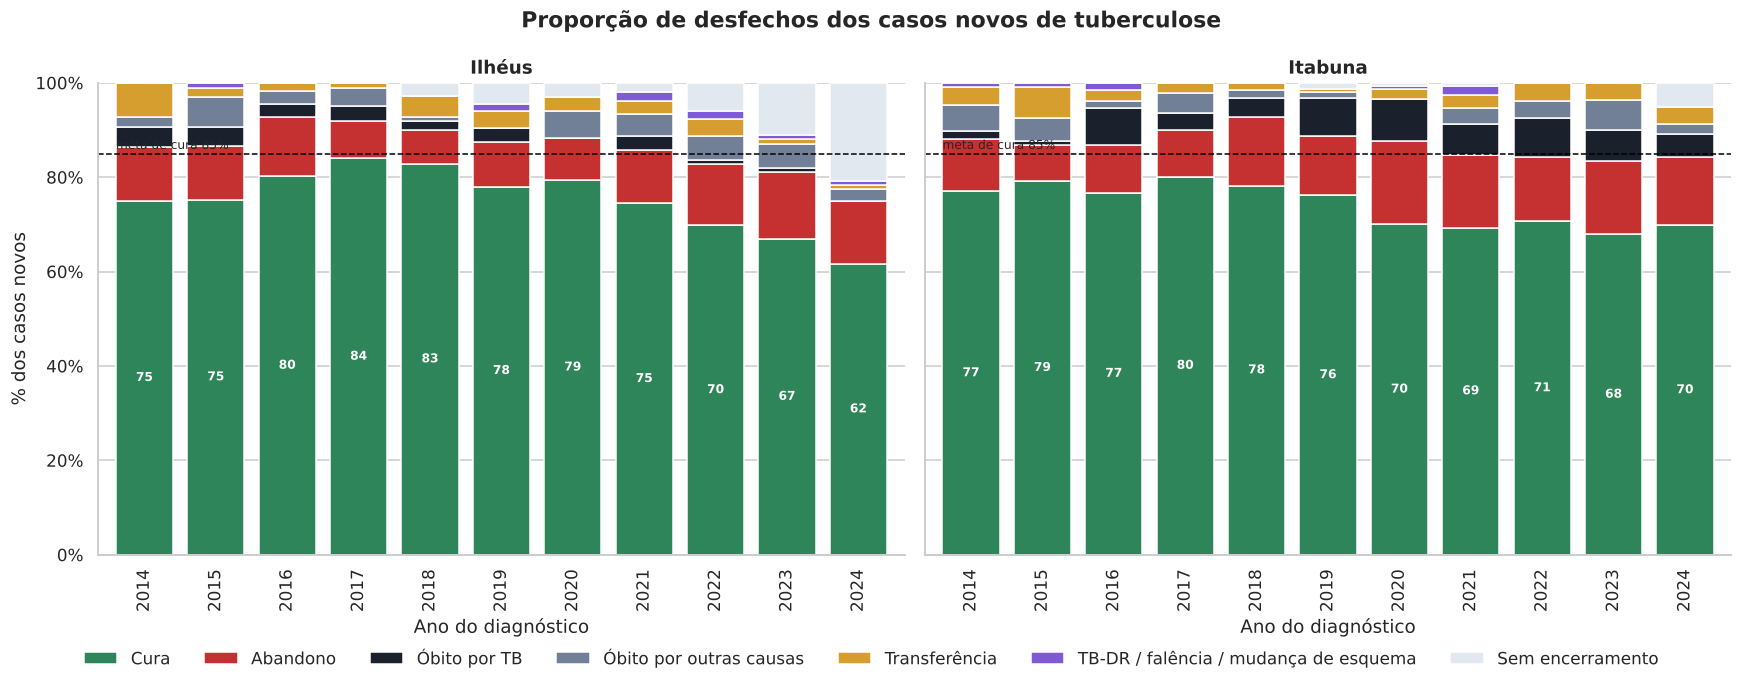

In [13]:
ordem = ['Cura', 'Abandono', 'Óbito por TB', 'Óbito por outras causas', 'Transferência',
         'TB-DR / falência / mudança de esquema', 'Sem encerramento']
cores_desf = ['#2f855a', '#c53030', '#1a202c', '#718096', '#d69e2e', '#805ad5', '#e2e8f0']
coorte = ii[ii['coorte_casos_novos']]
prop = (pd.crosstab(coorte['cidade'], coorte['desfecho_grupo'], normalize='index') * 100).reindex(columns=ordem).fillna(0)
display(prop.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, cidade in zip(axes, cidades):
    c = coorte[coorte['cidade'] == cidade]
    tab = (pd.crosstab(c['ano_diag'], c['desfecho_grupo'], normalize='index') * 100).reindex(columns=ordem).fillna(0)
    tab.plot(kind='bar', stacked=True, ax=ax, color=cores_desf, width=0.8, legend=False)
    for i, v in enumerate(tab['Cura']):
        ax.text(i, v / 2, f'{v:.0f}', ha='center', va='center', color='white', fontsize=8, fontweight='bold')
    ax.axhline(85, color='black', ls='--', lw=1); ax.text(-0.4, 86, 'meta de cura 85%', fontsize=8)
    ax.set_title(cidade); ax.set_xlabel('Ano do diagnóstico'); ax.set_ylabel('% dos casos novos')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=7, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Proporção de desfechos dos casos novos de tuberculose', fontweight='bold')
fig.tight_layout(); tb.salva_fig(fig, '10_proporcao_desfechos'); plt.show()

### 5.3 Desfecho x alcoolismo (em %)

Taxa de cura e de abandono **dentro** de cada grupo (alcoolista / não alcoolista), com IC 95% de Wilson.
Base: casos novos encerrados como cura ou abandono e com o campo alcoolismo preenchido.

,cidade,grupo,n,abandonos,abandono (%),ic_inf,ic_sup
0,Ilhéus,Alcoolista,212,53,25.0,19.7,31.2
1,Ilhéus,Não alcoolista,711,60,8.4,6.6,10.7
2,Itabuna,Alcoolista,132,46,34.8,27.3,43.3
3,Itabuna,Não alcoolista,972,129,13.3,11.3,15.5


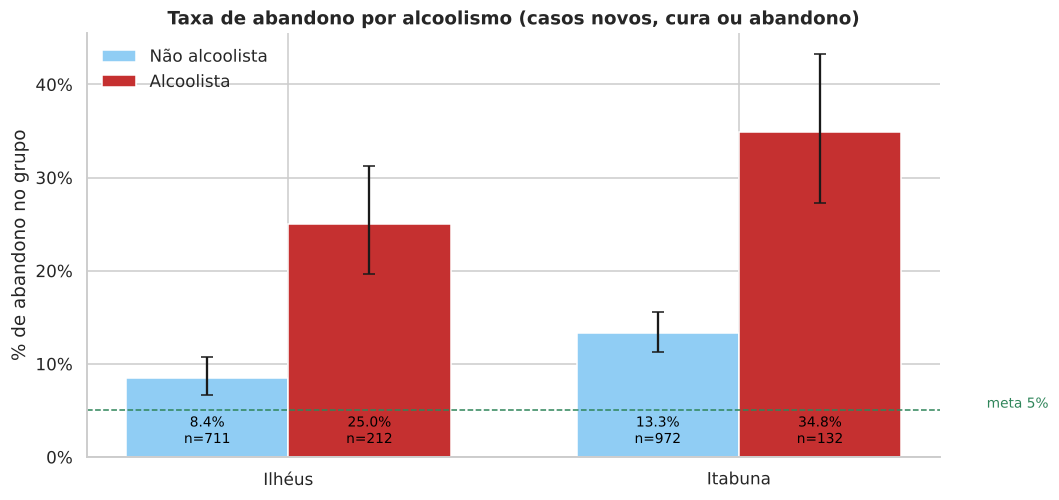

In [14]:
base = coorte[coorte['desfecho'].isin(['Cura', 'Abandono', 'Abandono primário']) & coorte['alcoolismo'].notna()].copy()
base['grupo'] = base['alcoolismo'].map({1.0: 'Alcoolista', 0.0: 'Não alcoolista'})
res = []
for (cidade, grupo), g in base.groupby(['cidade', 'grupo']):
    k, n = int(g['abandono'].sum()), len(g)
    lo, hi = tb.ic_proporcao(k, n)
    res.append({'cidade': cidade, 'grupo': grupo, 'n': n, 'abandonos': k, 'abandono (%)': 100 * k / n, 'ic_inf': lo, 'ic_sup': hi})
res = pd.DataFrame(res)
display(res.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(2); w = 0.36
for j, grupo in enumerate(['Não alcoolista', 'Alcoolista']):
    d = res[res['grupo'] == grupo].set_index('cidade').reindex(cidades)
    pos = x + (j - 0.5) * w
    ax.bar(pos, d['abandono (%)'], w, color=['#90cdf4', '#c53030'][j], label=grupo,
           yerr=[d['abandono (%)'] - d['ic_inf'], d['ic_sup'] - d['abandono (%)']], capsize=4)
    for xi, (v, n) in zip(pos, zip(d['abandono (%)'], d['n'])):
        ax.text(xi, 1, f'{v:.1f}%\nn={n}', ha='center', va='bottom', fontsize=9, color='black')
ax.axhline(5, color='#2f855a', ls='--', lw=1); ax.text(1.55, 5.3, 'meta 5%', color='#2f855a', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(cidades); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel('% de abandono no grupo'); ax.legend(frameon=False)
ax.set_title('Taxa de abandono por alcoolismo (casos novos, cura ou abandono)')
tb.salva_fig(fig, '10_abandono_alcoolismo'); plt.show()

### 5.4 Situação de rua + alcoolismo x abandono

Cada célula mostra a taxa de abandono e, embaixo, o número de pacientes. Células com menos de 10 pacientes
devem ser lidas com cautela.

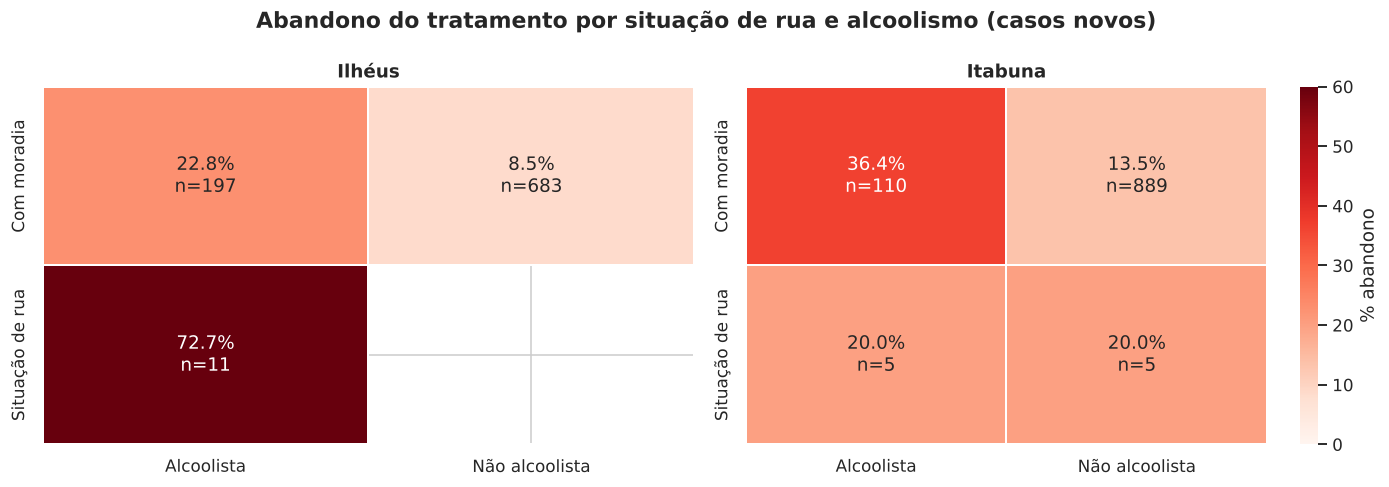

In [15]:
base2 = base[base['situacao_rua'].notna()].copy()
base2['moradia'] = base2['situacao_rua'].map({1.0: 'Situação de rua', 0.0: 'Com moradia'})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, cidade in zip(axes, cidades):
    g = base2[base2['cidade'] == cidade]
    taxa = g.pivot_table(index='moradia', columns='grupo', values='abandono', aggfunc='mean') * 100
    n = g.pivot_table(index='moradia', columns='grupo', values='abandono', aggfunc='size')
    rot = taxa.round(1).astype(str) + '%\nn=' + n.fillna(0).astype(int).astype(str)
    sns.heatmap(taxa, annot=rot, fmt='', cmap='Reds', vmin=0, vmax=60, ax=ax, cbar=cidade == 'Itabuna',
                cbar_kws={'label': '% abandono'}, linewidths=1, linecolor='white')
    ax.set_title(cidade); ax.set_xlabel(''); ax.set_ylabel('')
fig.suptitle('Abandono do tratamento por situação de rua e alcoolismo (casos novos)', fontweight='bold')
fig.tight_layout(); tb.salva_fig(fig, '10_rua_alcool_abandono'); plt.show()

## 6. Números-chave para a conclusão

In [16]:
r = rt.set_index('comparação')
pp = painel_periodo
print(f"Incidência média 2014-2024: Itabuna {r.loc['Itabuna / Ilhéus', 'taxa média Itabuna']:.1f} x "
      f"Ilhéus {r.loc['Itabuna / Ilhéus', 'taxa média Ilhéus']:.1f} por 100 mil "
      f"(razão {r.loc['Itabuna / Ilhéus', 'razão de taxas']:.2f}; p = {tb.fmt_p(r.loc['Itabuna / Ilhéus', 'p'])})")
print(f"Bahia no mesmo período: {r.loc['Itabuna / Bahia', 'taxa média Bahia']:.1f} por 100 mil")
for cidade in cidades:
    print(f"{cidade}: cura {pp.loc['cura (%)', cidade]:.1f}%, abandono {pp.loc['abandono (%)', cidade]:.1f}%, "
          f"óbito por TB {pp.loc['óbito por TB (%)', cidade]:.1f}%, testagem HIV {pp.loc['testagem HIV (%)', cidade]:.1f}%, "
          f"contatos examinados {pp.loc['contatos examinados (%)', cidade]:.1f}%")

Incidência média 2014-2024: Itabuna 70.5 x Ilhéus 58.6 por 100 mil (razão 1.20; p = <0,001)
Bahia no mesmo período: 30.4 por 100 mil
Ilhéus: cura 78.8%, abandono 11.6%, óbito por TB 2.3%, testagem HIV 63.1%, contatos examinados 48.6%
Itabuna: cura 74.5%, abandono 13.2%, óbito por TB 5.8%, testagem HIV 70.3%, contatos examinados 33.3%


## Conclusões

1. **Carga da doença.** Itabuna teve incidência média de 70,5 casos novos por 100 mil habitantes e Ilhéus de 58,6
   (razão de taxas 1,20; IC 95% 1,11–1,30). As duas ficam perto do **dobro da Bahia** (30,4) e acima do Brasil.
2. **Pandemia.** Em 2020 a incidência de Ilhéus caiu de 75,5 para 37,9, enquanto Itabuna ficou estável (77,5).
   Em 2023 houve queda nas duas cidades (investigada no notebook 13).
3. **Metas.** Nenhuma cidade atinge a meta de cura de 85% no período (Ilhéus 78,8%, Itabuna 74,5%), e o abandono
   fica em 11,6% e 13,2%, mais que o dobro da meta de 5%. O óbito por TB em Itabuna (5,8%) é 2,5 vezes o de Ilhéus.
4. **Diagnóstico e vigilância.** Testagem para HIV (63% e 70%) e exame de contatos (49% e 33%) ficam abaixo das
   metas. Ilhéus faz cultura em 42% dos casos pulmonares, Itabuna em 16%. O teste rápido molecular aparece como
   realizado em só 1% a 2% das fichas, o que sugere sub-registro do TRM, e não ausência do exame.
5. **TDO é, em boa parte, um problema de registro.** Em Itabuna o campo ficou vazio em quase todas as fichas de
   2016 a 2020 (só 46,5% preenchido no período) e o "sim" praticamente desaparece depois de 2014, quando era
   registrado no campo antigo. A eficácia do TDO não pode ser comparada entre as cidades com esses dados.
6. **Alcoolismo.** O abandono entre alcoolistas é 3 vezes maior em Ilhéus (25,0% x 8,4%) e 2,6 vezes maior em
   Itabuna (34,8% x 13,3%). Os testes formais estão no notebook 11 e o efeito ajustado no notebook 12.